In [1]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,Radar
from util.overshoots import local_safety, critical_parameter, OS_model

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr

from matplotlib.colors import LinearSegmentedColormap
import colorcet as cc

# Using PROVIDE Project scenarios
Robin Lamboll, Joeri Rogelj, & Carl-Friedrich Schleussner. (2025). Scenario emissions and temperature data for PROVIDE project (v1.3.0) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.11108741

https://pure.iiasa.ac.at/id/eprint/18130/1/essoar.10511875.2.pdf for description

https://zenodo.org/records/11108741 for actual data set

In [2]:
folder = '../../Data/PROVIDE 2025/'
cols = list(pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',nrows=1))
df = pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',
                 usecols = [c for c in cols if (c != 'quantile') and (c!= 'atomic_scen')]).set_index('scenario').T
df.index.names=['year']
# df=df.rename(columns={'scenario':''})
scenarios = df.columns.values

In [3]:
print(scenarios)

['CurPol_SAP' 'CurPol_OS_1.5C' 'ModAct_OS_1.5C' 'ModAct_OS_1C'
 'ModAct_SAP' 'ssp534-over' 'Neg_SAP' 'GS_NZGHG' 'Ren_NZCO2' 'Neg_NZGHG'
 'Ref_1p5' 'Neg_OS_0C' 'LD_NZGHG' 'SP_NZGHG' 'ssp119']


# Using GTPR2025 TEs

In [5]:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='GTPR25')
df_TEs[['Threshold (°C) – Min.', 
        'Threshold (°C) – Est.', 
        'Threshold (°C) – Max.']] = df_TEs[['Threshold (°C) – Min.', 
                                            'Threshold (°C) – Est.', 
                                            'Threshold (°C) – Max.']].interpolate(method='linear', axis=1, limit_direction='backward')
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

# Loading pre-saved interaction matrices
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

In [6]:
print(df_TEs.index.to_numpy())

['AMAZ' 'AMOC' 'ASI' 'ENSO' 'GIS' 'PERM' 'REEF' 'WAIS' 'WAM']


# 1D perturbations around baseline

## 1D perturbations around popt

In [7]:
scenarios

array(['CurPol_SAP', 'CurPol_OS_1.5C', 'ModAct_OS_1.5C', 'ModAct_OS_1C',
       'ModAct_SAP', 'ssp534-over', 'Neg_SAP', 'GS_NZGHG', 'Ren_NZCO2',
       'Neg_NZGHG', 'Ref_1p5', 'Neg_OS_0C', 'LD_NZGHG', 'SP_NZGHG',
       'ssp119'], dtype=object)

Text(0.5, 0, 'Year')

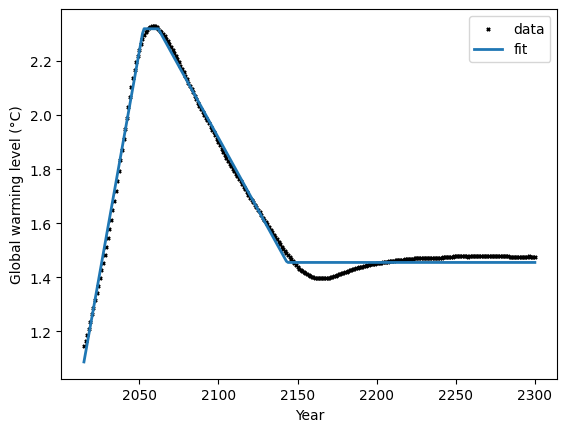

In [101]:
baseline = 'ssp534-over'
temp = df[baseline].to_numpy()
t_ref=2015
T_ref=temp[t_ref-1850]
T_max=temp.max()
xdata = np.arange(t_ref,2301)-t_ref
ydata=temp[t_ref-1850:]
popt, pcov = curve_fit(OS_model, xdata, ydata,
                       p0=[T_ref, T_max, temp[-1], (T_max-T_ref)/0.01, 10 ,(temp.max()-T_ref)/0.01],
                       bounds = ([T_ref-0.5, T_max-0.5, temp[-1]-0.5, 10, 0, 10],
                                 [T_ref+0.5, T_max+0.5, temp[-1]+0.5, len(ydata), 100, len(ydata)]) )
plt.scatter(xdata+t_ref,ydata,marker='x',s=5,c='k',label='data')
plt.plot(xdata+t_ref,OS_model(xdata,*popt),label='fit',lw=2)
plt.legend()
plt.ylabel('Global warming level (°C)')
plt.xlabel('Year')

In [9]:
popt

array([  1.10009253,   3.30206669,   1.50422   , 103.28176735,
         3.4404387 , 163.72772026])

In [102]:
T_0s = np.arange(0,5.1,step=0.1)
T_peaks = np.arange(0,5.1,step=0.1)
T_oss = np.arange(0,5.1,step=0.1)

# t_ups = np.arange(50,151,step=5)
# t_plats = np.arange(0,101,step=5)
# t_downs = np.arange(100,201,step=5)

t_ups = np.arange(0,201,step=10)
t_plats = np.arange(0,201,step=10)
t_downs = np.arange(0,201,step=10)

pars = [T_0s, T_peaks, T_oss, t_ups, t_plats, t_downs]

years = np.arange(2015,2301)
no_years=len(years)

pcs = [np.ones((len(p),no_years,len(df_TEs)))*q_c.reshape((1,1,len(df_TEs))) for p in pars]
prs = [np.ones((len(p),no_years,len(df_TEs)))*q_r.reshape((1,1,len(df_TEs))) for p in pars]

temps = [np.zeros((len(pars[i]),no_years)) for i in range(len(popt))]
for i in range(len(popt)):
    PAR = np.copy(popt)
    for j,p_j in enumerate(pars[i]):
        PAR[i] = p_j
        temps[i][j,:] = OS_model(xdata,*PAR)
        for t in range(no_years):
            pcs[i][j,t,:] *= temp_response(temps[i][j,t], T_lim, betas)
            prs[i][j,t,:] *= 1-temp_response(temps[i][j,t], T_lim, betas)

C:\Users\baraj\Documents\Code\NMaCh-TP\Code\Notebooks\..\util\overshoots.py:179: RuntimeWarning: invalid value encountered in divide
  out = T_0 + t[t<=t_up]*(T_peak-T_0)/t_up


## Historical data to burn in and get initial condition for 2015

In [103]:
years_burn_in = np.arange(1850,2016) # up to and including 2015
no_burn_years = len(years_burn_in)
pc_burn = np.ones((no_burn_years,len(df_TEs)))
pc_burn *= q_c
pr_burn = np.ones((no_burn_years,len(df_TEs)))
pr_burn *= q_r
for t in years_burn_in-1850:
    pc_burn[t,:] *= temp_response(temp[t], T_lim, betas)
    pr_burn[t,:] *= (1-temp_response(temp[t], T_lim, betas))

D_burn = np.zeros((len_sample,len(df_TEs)))
D_burn_noint = np.zeros(len(df_TEs))

In [104]:
for r in tqdm.tqdm(range(len_sample)):
    for t in range(1,no_burn_years):
        D_burn[r,:] = environmental_update(D_burn[r,:],
                                           A[r],
                                           pc=pc_burn[t,:],
                                           pr=pr_burn[t,:])
for t in tqdm.tqdm(range(1,no_burn_years)):
    D_burn_noint = environmental_update(D_burn_noint,
                                        np.zeros((len(df_TEs),len(df_TEs))),
                                        pc=pc_burn[t,:],
                                        pr=pr_burn[t,:])

100%|█████████████████████████████████████████████████████████████████████████████| 165/165 [00:00<00:00, 29895.90it/s]


In [106]:
years = np.arange(2015,2301)
no_years=len(years)
D = [np.zeros((len(pars[i]),len_sample,len(df_TEs),no_years)) for i in range(len(popt))]
D_noint = [np.zeros((len(pars[i]),len(df_TEs),no_years)) for i in range(len(popt))]

for i in range(len(popt)):
    for r in range(len_sample):
        D[i][:,r,:,0] = D_burn[r,:]
    D_noint[i][:,:,0] = D_burn_noint[:]

In [107]:
for i in range(len(popt)):
    for j in tqdm.tqdm(range(len(pars[i]))):
        for t in range(1,no_years):
            D_noint[i][j,:,t] = environmental_update(D_noint[i][j,:,t-1],
                                                     np.zeros((len(df_TEs),len(df_TEs))),
                                                     pc=pcs[i][j,t,:],pr=prs[i][j,t,:])
            for r in range(len_sample):
                D[i][j,r,:,t] = environmental_update(D[i][j,r,:,t-1],A[r],
                                                     pc=pcs[i][j,t,:],pr=prs[i][j,t,:])

100%|██████████████████████████████████████████████████████████████████████████████████| 21/21 [00:44<00:00,  2.14s/it]


## Saving simulations as .zarr

In [46]:
folder = '../../Data/Simulations/Overshoots/perturb_around_baseline/'+baseline+'/'
if not os.path.exists(folder):
    os.makedirs(folder)

par_files = ['temp_0','temp_peak','temp_os',
             'time_up','time_plat','time_down']   

In [47]:
for i in range(len(popt)):
    attrs = {par_files[j]: popt[j] for j in range(len(popt)) if j!=i}
    attrs['description']="Risk of being in the degraded state, as parameter, %s, is varied. \n"%(par_files[i])
    for j in range(len(popt)):
        if j != i:
            attrs['description'] += par_files[j] + ' = ' + str(popt[j]) + "\n"
    ds = xr.Dataset(
        data_vars = dict(
            risk = (['parameter', 'interaction_mat', 'tipping_element', 'year'],D[i]), 
            risk_noint = (['parameter', 'tipping_element', 'year'],D_noint[i])
        ), 
        coords = dict(
            parameter = pars[i], 
            interaction_mat=np.arange(len_sample), 
            tipping_element=df_TEs.index.to_numpy(),
            year=years
        ), 
        attrs=attrs,
    )
    ds.to_zarr(folder+par_files[i]+'.zarr',mode='w');
    # ds.to_netcdf(folder+par_files[i]+'.nc',mode='w');

/home/jbara/Code/my-venv/lib/python3.12/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/home/jbara/Code/my-venv/lib/python3.12/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/home/jbara/Code/my-venv/lib/python3.12/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/home/jbara/Code/my-venv/lib/python3.12/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Za

# OLD plotting

In [107]:
baseline = 'CurPol_OS_1.5C'
folder = '../../Data/Simulations/Overshoots/perturb_around_baseline/'+baseline+'/'
par_files = ['temp_0','temp_peak','temp_os',
             'time_up','time_plat','time_down']   
ds_D = [xr.open_zarr(folder+par_files[i]+'.zarr') for i in range(6)]
pars = [ds.parameter.to_numpy() for ds in ds_D]
D = [ds.risk.to_numpy() for ds in ds_D]

In [16]:
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.cm import ScalarMappable

In [204]:
df_TEs.index.values

array(['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS',
       'WAM'], dtype=object)

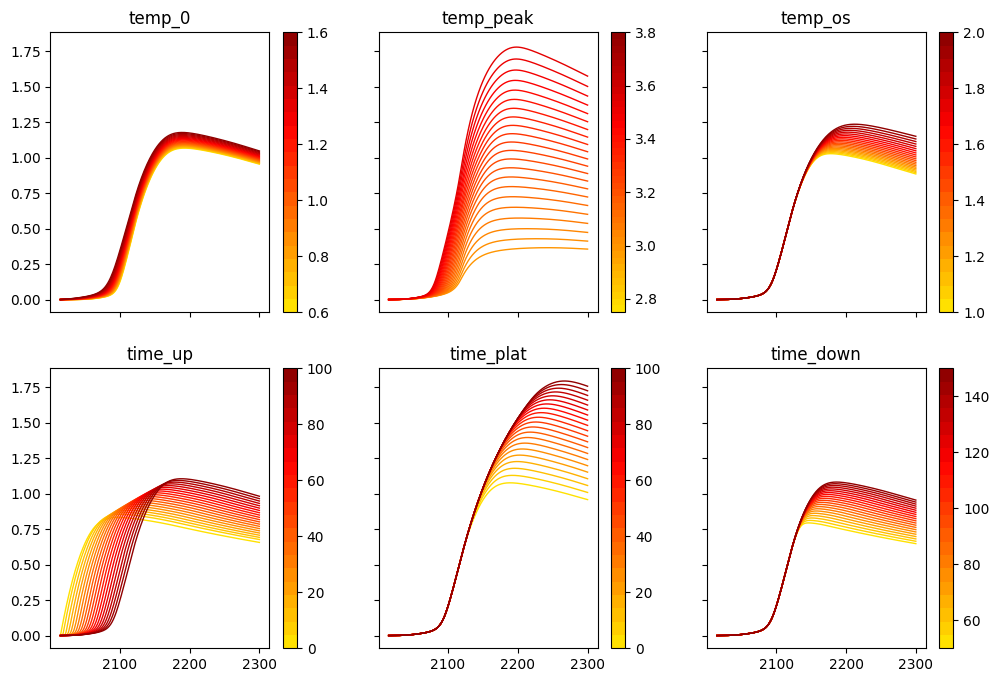

In [40]:
years = np.arange(2015,2301)

fig,axs = plt.subplots(nrows=2,ncols=3,figsize=(12,8),sharex=True,sharey=True)
for i in range(6):
    axs[i//3,i%3].set_title(par_files[i])
    # a,b=0,20
    if i == 1:
        a,b = 9,31
    else:
        a,b=0,21
    colors = plt.cm.hot(np.linspace(0.2,0.7,len(pars[i])))[::-1]
    cmap = LinearSegmentedColormap.from_list('my_cmap', colors, N=colors.shape[0])
    for j in range(a,b):#len(pars[i])):
        # axs[i//3,i%3].plot(years,D_noint[i][j,:,:].sum(axis=0),c='k',lw=0.5)
        axs[i//3,i%3].plot(years,D[i][j,:,:,:].mean(axis=0).sum(axis=0) - D[i][j,:,-3,:].mean(axis=0),c=colors[j,:],lw=1)
    fig.colorbar(ScalarMappable(cmap=cmap, norm=plt.Normalize(pars[i][a], pars[i][b-1])),ax=axs[i//3,i%3])

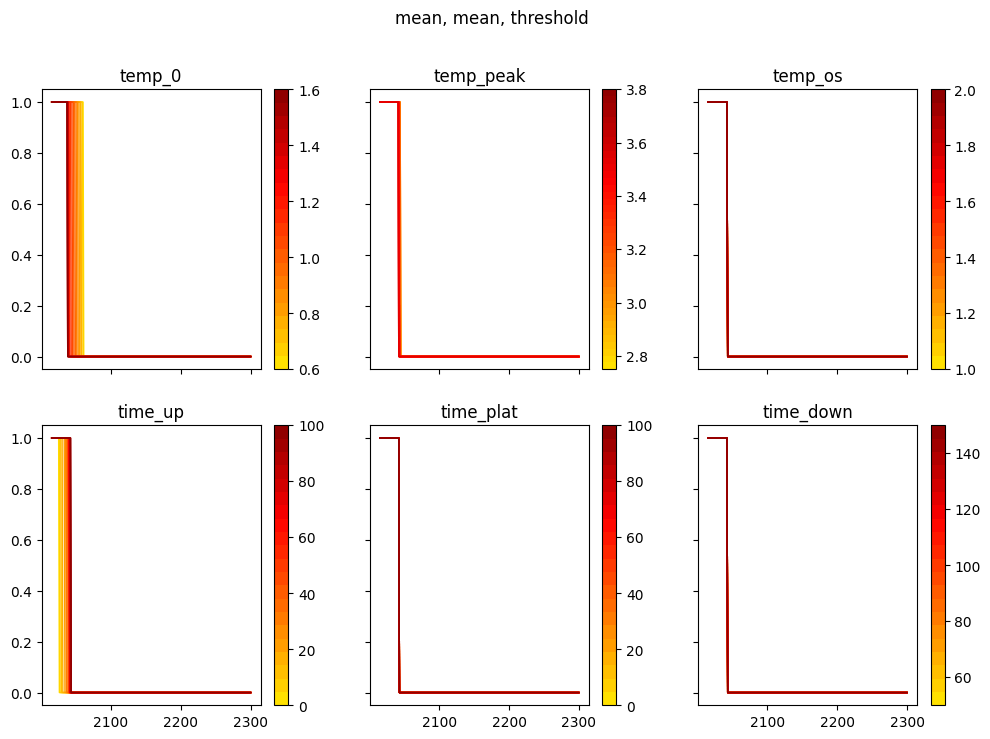

In [270]:
fig,axs = plt.subplots(nrows=2,ncols=3,figsize=(12,8),sharex=True,sharey=True)
plt.suptitle("mean, mean, threshold")
sos_threshold=0.1
for i in range(6):
    axs[i//3,i%3].set_title(par_files[i])
    # a,b=0,20
    if i == 1:
        a,b = 9,31
    else:
        a,b=0,21
    colors = plt.cm.hot(np.linspace(0.2,0.7,len(pars[i])))[::-1]
    cmap = LinearSegmentedColormap.from_list('my_cmap', colors, N=colors.shape[0])
    for j in range(a,b):#len(pars[i])):
        # axs[i//3,i%3].plot(years,D_noint[i][j,:,:].sum(axis=0),c='k',lw=0.5)
        axs[i//3,i%3].plot(years,
                           (D[i][j,:,:,:].mean(axis=0).mean(axis=0))<=sos_threshold,
                            c=colors[j,:],lw=1)
    fig.colorbar(ScalarMappable(cmap=cmap, norm=plt.Normalize(pars[i][a], pars[i][b-1])),ax=axs[i//3,i%3])

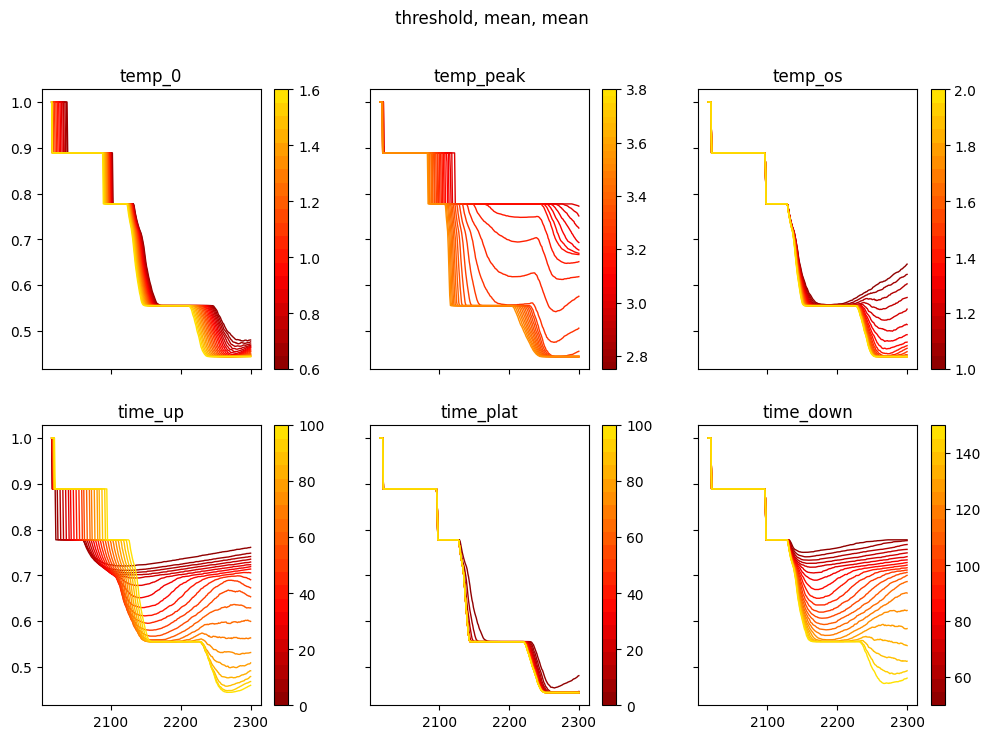

In [271]:
fig,axs = plt.subplots(nrows=2,ncols=3,figsize=(12,8),sharex=True,sharey=True)
sos_threshold=0.1
plt.suptitle("threshold, mean, mean")
for i in range(6):
    axs[i//3,i%3].set_title(par_files[i])
    # a,b=0,20
    if i == 1:
        a,b = 9,31
    else:
        a,b=0,21
    colors = plt.cm.hot(np.linspace(0.2,0.7,len(pars[i])))#[::-1]
    cmap = LinearSegmentedColormap.from_list('my_cmap', colors, N=colors.shape[0])
    for j in range(a,b):#len(pars[i])):
        # axs[i//3,i%3].plot(years,D_noint[i][j,:,:].sum(axis=0),c='k',lw=0.5)
        axs[i//3,i%3].plot(years,
                           (D[i][j,:,:,:]<=sos_threshold).mean(axis=0).mean(axis=0),c=colors[j,:],lw=1)
    fig.colorbar(ScalarMappable(cmap=cmap, norm=plt.Normalize(pars[i][a], pars[i][b-1])),ax=axs[i//3,i%3])

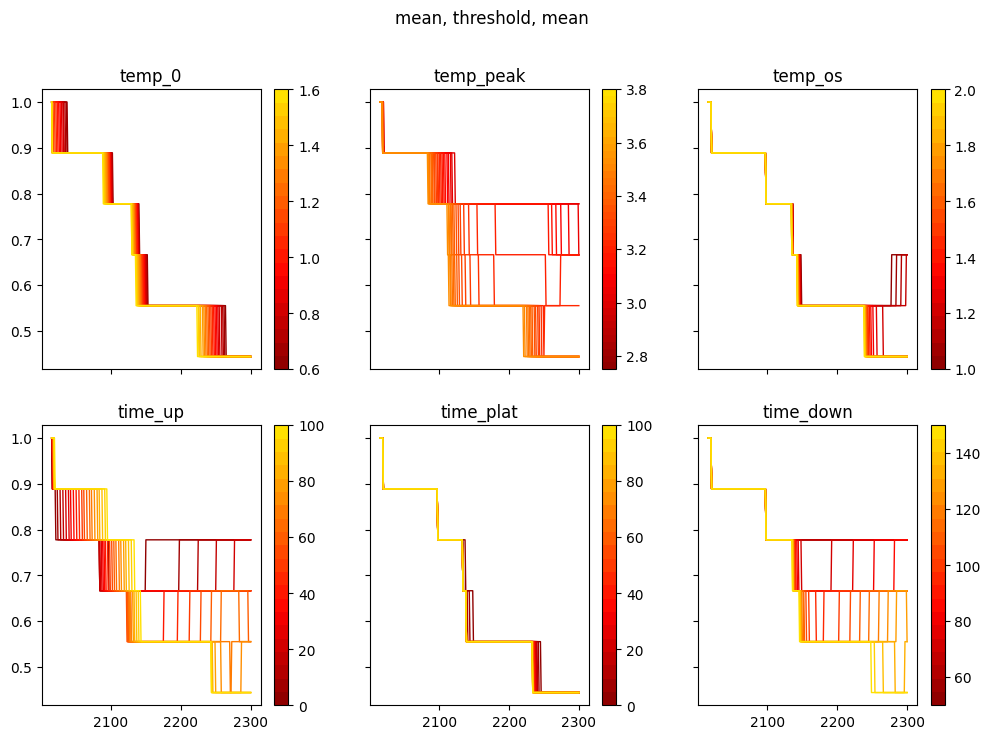

In [272]:
fig,axs = plt.subplots(nrows=2,ncols=3,figsize=(12,8),sharex=True,sharey=True)
sos_threshold=0.1
plt.suptitle("mean, threshold, mean")
for i in range(6):
    axs[i//3,i%3].set_title(par_files[i])
    # a,b=0,20
    if i == 1:
        a,b = 9,31
    else:
        a,b=0,21
    colors = plt.cm.hot(np.linspace(0.2,0.7,len(pars[i])))#[::-1]
    cmap = LinearSegmentedColormap.from_list('my_cmap', colors, N=colors.shape[0])
    for j in range(a,b):#len(pars[i])):
        # axs[i//3,i%3].plot(years,D_noint[i][j,:,:].sum(axis=0),c='k',lw=0.5)
        axs[i//3,i%3].plot(years,
                           (D[i][j,:,:,:].mean(axis=0)<=sos_threshold).mean(axis=0),c=colors[j,:],lw=1)
    fig.colorbar(ScalarMappable(cmap=cmap, norm=plt.Normalize(pars[i][a], pars[i][b-1])),ax=axs[i//3,i%3])

In [274]:
D[0].shape

(21, 500, 9, 286)

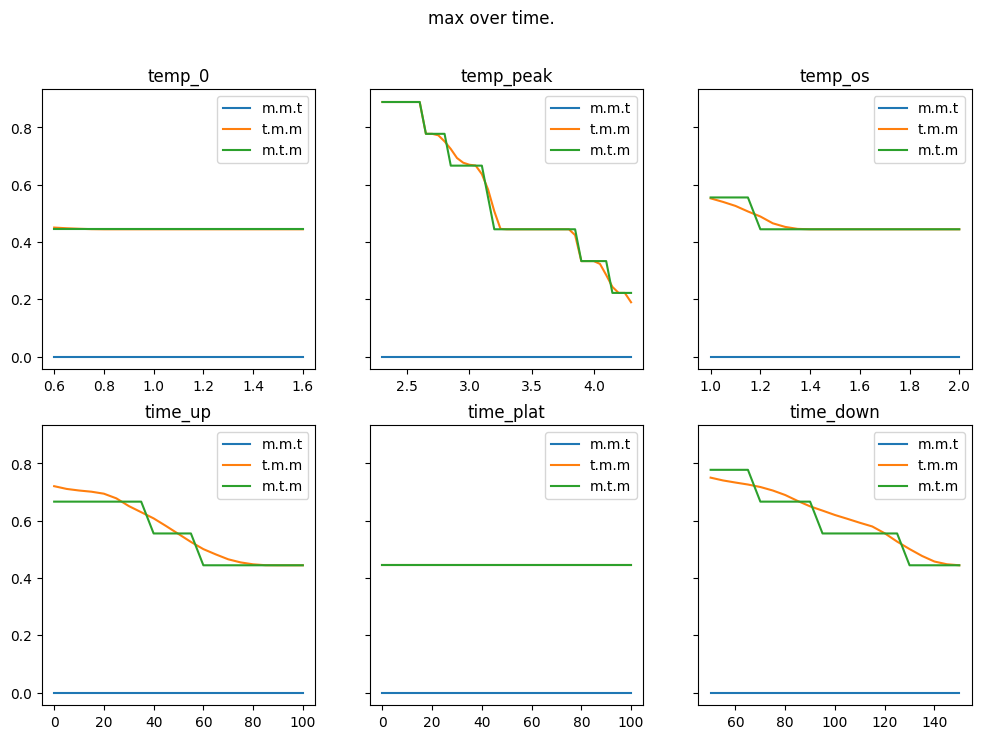

In [283]:
fig,axs = plt.subplots(nrows=2,ncols=3,figsize=(12,8),sharex=False,sharey=True)
sos_threshold=0.1
fig.suptitle("max over time.")
for i in range(6):
    axs[i//3,i%3].set_title(par_files[i])
    axs[i//3,i%3].plot(pars[i],
                       D[i].max(axis=-1).mean(axis=(1,2)) <=sos_threshold,label='m.m.t')
    axs[i//3,i%3].plot(pars[i],
                       (D[i].max(axis=-1)<=sos_threshold).mean(axis=(1,2)),label='t.m.m')
    axs[i//3,i%3].plot(pars[i],
                       (D[i].max(axis=-1).mean(axis=1)<=sos_threshold).mean(axis=1),label='m.t.m')
    axs[i//3,i%3].legend()
    
    # fig.colorbar(ScalarMappable(cmap=cmap, norm=plt.Normalize(pars[i][a], pars[i][b-1])),ax=axs[i//3,i%3])

In [286]:
popt

array([  1.10009253,   3.30206671,   1.50422   , 103.28176816,
         3.44043629, 163.72772189])

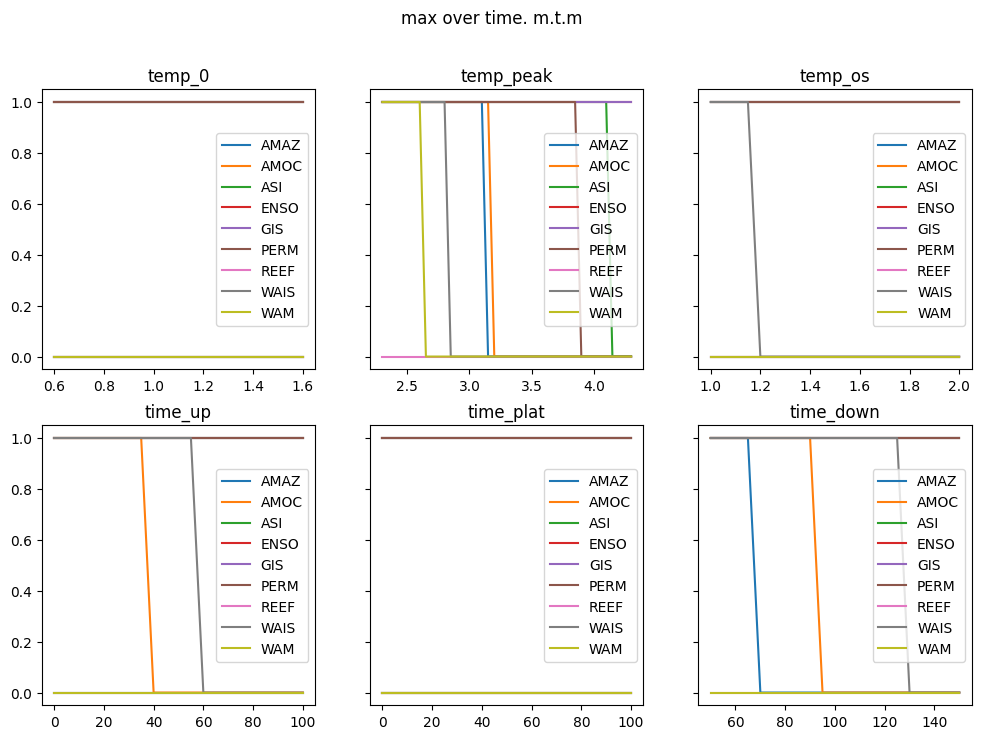

In [285]:
fig,axs = plt.subplots(nrows=2,ncols=3,figsize=(12,8),sharex=False,sharey=True)
sos_threshold=0.1
fig.suptitle("max over time. m.t.m")
TEs=df_TEs.index.to_numpy()
for i in range(6):
    axs[i//3,i%3].set_title(par_files[i])

    for j in range(len(TEs)):
        axs[i//3,i%3].plot(pars[i],
                           (D[i].max(axis=-1).mean(axis=1)<=sos_threshold)[:,j],label=TEs[j])
    axs[i//3,i%3].legend()
    
    # fig.colorbar(ScalarMappable(cmap=cmap, norm=plt.Normalize(pars[i][a], pars[i][b-1])),ax=axs[i//3,i%3])

In [26]:
from matplotlib.patches import Circle, RegularPolygon
from matplotlib.path import Path
from matplotlib.projections import register_projection
from matplotlib.projections.polar import PolarAxes
from matplotlib.spines import Spine
from matplotlib.transforms import Affine2D


def radar_factory(num_vars, frame='circle'):
    """
    Create a radar chart with `num_vars` Axes.

    This function creates a RadarAxes projection and registers it.

    Parameters
    ----------
    num_vars : int
        Number of variables for radar chart.
    frame : {'circle', 'polygon'}
        Shape of frame surrounding Axes.

    """
    # calculate evenly-spaced axis angles
    theta = np.linspace(0, 2*np.pi, num_vars, endpoint=False)

    class RadarTransform(PolarAxes.PolarTransform):

        def transform_path_non_affine(self, path):
            # Paths with non-unit interpolation steps correspond to gridlines,
            # in which case we force interpolation (to defeat PolarTransform's
            # autoconversion to circular arcs).
            if path._interpolation_steps > 1:
                path = path.interpolated(num_vars)
            return Path(self.transform(path.vertices), path.codes)

    class RadarAxes(PolarAxes):

        name = 'radar'
        PolarTransform = RadarTransform

        def __init__(self, *args, **kwargs):
            super().__init__(*args, **kwargs)
            # rotate plot such that the first axis is at the top
            self.set_theta_zero_location('N')

        def fill(self, *args, closed=True, **kwargs):
            """Override fill so that line is closed by default"""
            return super().fill(closed=closed, *args, **kwargs)

        def plot(self, *args, **kwargs):
            """Override plot so that line is closed by default"""
            lines = super().plot(*args, **kwargs)
            for line in lines:
                self._close_line(line)

        def _close_line(self, line):
            x, y = line.get_data()
            # FIXME: markers at x[0], y[0] get doubled-up
            if x[0] != x[-1]:
                x = np.append(x, x[0])
                y = np.append(y, y[0])
                line.set_data(x, y)

        def set_varlabels(self, labels):
            self.set_thetagrids(np.degrees(theta), labels)

        def _gen_axes_patch(self):
            # The Axes patch must be centered at (0.5, 0.5) and of radius 0.5
            # in axes coordinates.
            if frame == 'circle':
                return Circle((0.5, 0.5), 0.5)
            elif frame == 'polygon':
                return RegularPolygon((0.5, 0.5), num_vars,
                                      radius=.5, edgecolor="k")
            else:
                raise ValueError("Unknown value for 'frame': %s" % frame)

        def _gen_axes_spines(self):
            if frame == 'circle':
                return super()._gen_axes_spines()
            elif frame == 'polygon':
                # spine_type must be 'left'/'right'/'top'/'bottom'/'circle'.
                spine = Spine(axes=self,
                              spine_type='circle',
                              path=Path.unit_regular_polygon(num_vars))
                # unit_regular_polygon gives a polygon of radius 1 centered at
                # (0, 0) but we want a polygon of radius 0.5 centered at (0.5,
                # 0.5) in axes coordinates.
                spine.set_transform(Affine2D().scale(.5).translate(.5, .5)
                                    + self.transAxes)
                return {'polar': spine}
            else:
                raise ValueError("Unknown value for 'frame': %s" % frame)

    register_projection(RadarAxes)
    return theta

In [28]:
def local_safety(D,safety_threshold=0.1,
              dimension_kw=dict(year=-1,sample=1)):
    return np.max(D,axis=dimension_kw['year'],keepdims=True).mean(axis=dimension_kw['sample'],keepdims=True)<=safety_threshold

## Plotting spider charts

In [42]:
r_data = np.array([np.max(np.squeeze(local_safety(D[i]))*pars[i].reshape(len(pars[i]),1),axis=0) for i in range(len(popt))])
# # ls = np.squeeze(local_safety(D[i]))
print(r_data)

[[  0.     0.     1.6    1.6    1.6    1.6    0.     0.     0.  ]
 [  3.1    3.15   4.1    4.3    4.3    3.85   0.     2.8    2.6 ]
 [  0.     0.     2.     2.     2.     2.     0.     1.15   0.  ]
 [  0.    35.   100.   100.   100.   100.     0.    55.     0.  ]
 [  0.     0.   100.   100.   100.   100.     0.     0.     0.  ]
 [ 65.    90.   150.   150.   150.   150.     0.   125.     0.  ]]


In [43]:
np.sort(r_data,axis=1)

array([[  0.  ,   0.  ,   0.  ,   0.  ,   0.  ,   1.6 ,   1.6 ,   1.6 ,
          1.6 ],
       [  0.  ,   2.6 ,   2.8 ,   3.1 ,   3.15,   3.85,   4.1 ,   4.3 ,
          4.3 ],
       [  0.  ,   0.  ,   0.  ,   0.  ,   1.15,   2.  ,   2.  ,   2.  ,
          2.  ],
       [  0.  ,   0.  ,   0.  ,  35.  ,  55.  , 100.  , 100.  , 100.  ,
        100.  ],
       [  0.  ,   0.  ,   0.  ,   0.  ,   0.  , 100.  , 100.  , 100.  ,
        100.  ],
       [  0.  ,   0.  ,  65.  ,  90.  , 125.  , 150.  , 150.  , 150.  ,
        150.  ]])

In [527]:
folder_out = '../../Figures/Overshoots/perturb_around_baseline/'+baseline+'/'
if not os.path.exists(folder_out):
    os.makedirs(folder_out)

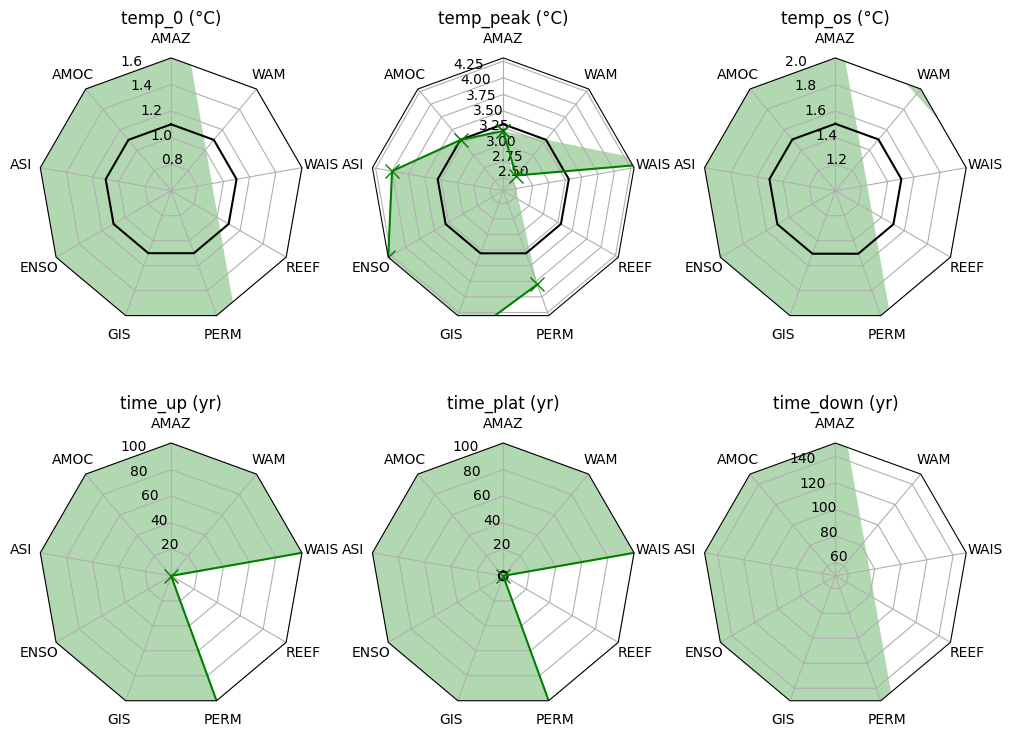

In [41]:
TEs = df_TEs.index.values
N = len(TEs)#len(popt)
theta = radar_factory(N, frame='polygon')
fig, axs = plt.subplots(figsize=(12, 9),nrows=2,ncols=3,
                            subplot_kw=dict(projection='radar'))
fig.subplots_adjust(wspace=0.25, hspace=0.15, top=0.85, bottom=0.05)
units= [' (°C)', ' (yr)']

for i in range(len(popt)):
    axs[i//3,i%3].plot(theta,[popt[i]]*N,color='k')
    axs[i//3,i%3].plot(theta,r_data[i,:],color='g',marker='x',markersize=10)
    axs[i//3,i%3].fill(theta,r_data[i,:],facecolor='g',alpha=0.3,label='_nolegend_')
    axs[i//3,i%3].set_xticks(theta,TEs)
    axs[i//3,i%3].set_ylim(pars[i][0],pars[i][-1])
    # if i==1:
        # axs[i//3,i%3].set_ylim(min(popt[0],popt[2]),pars[i][-1])
    axs[i//3,i%3].set_title(par_files[i] + units[i//3])
# ax.set_varlabels(spoke_labels)
# fig.savefig(folder_out+'six_spiders.png',bbox_inches='tight')

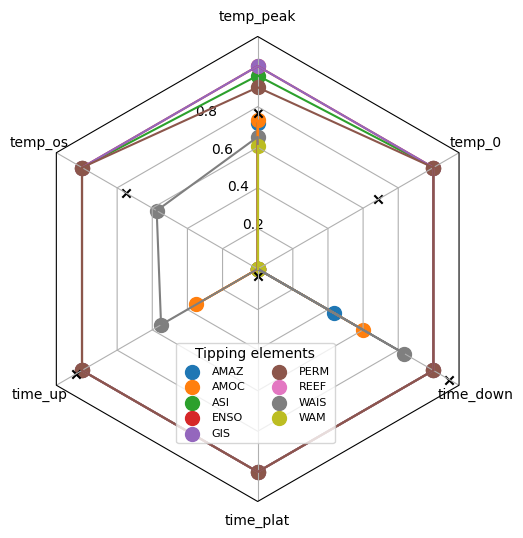

In [44]:
r_normed = np.copy(r_data)
for i in range(len(popt)):
    r_normed[i,:] /= pars[i][-1]

N = len(popt)
theta = radar_factory(N, frame='polygon')
fig, ax = plt.subplots(figsize=(6,6),nrows=1,ncols=1,
                            subplot_kw=dict(projection='radar'))
fig.subplots_adjust(wspace=0.25, hspace=0.20, top=0.85, bottom=0.05)

spoke_labels = par_files

# for ax, (title, case_data) in zip(axs.flat, data):
# ax.set_theta_zero_location(')
ax.set_rgrids([0.2, 0.4, 0.6, 0.8])
# ax.set_title(title, weight='bold', size='medium', position=(0.5, 1.1),
#              horizontalalignment='center', verticalalignment='center')
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
reorder = [5,0,1,2,3,4]
for i in range(len(TEs)):
    # ax.fill(theta[reorder], r_normed[:,i], facecolor=colors[i], alpha=0.1, label='_nolegend_');
    ax.plot(theta[reorder], r_normed[:,i], color=colors[i],label='_nolegend_');
    ax.scatter(theta[reorder], r_normed[:,i], color=colors[i],marker='o',s=100,label=TEs[i]);
ax.set_xticks(theta[reorder],par_files)
# ax.set_ylim(0.01,1)
# ax.set_varlabels(spoke_labels)
ax.legend(loc=(0.325,0.125),ncols=2,title='Tipping elements',fontsize=8)
ax.scatter(theta[reorder],[popt[i]/pars[i][-1] for i in range(N)],color='k',marker='x')
# fig.savefig(folder_out+'single_spider.png',bbox_inches='tight')

In [49]:
import matplotlib as mpl

In [61]:
r_sn

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        1.        , 1.        , 1.        , 1.        ],
       [0.        , 0.60465116, 0.65116279, 0.72093023, 0.73255814,
        0.89534884, 0.95348837, 1.        , 1.        ],
       [0.        , 0.        , 0.        , 0.        , 0.575     ,
        1.        , 1.        , 1.        , 1.        ],
       [0.        , 0.        , 0.        , 0.35      , 0.55      ,
        1.        , 1.        , 1.        , 1.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        1.        , 1.        , 1.        , 1.        ],
       [0.        , 0.        , 0.43333333, 0.6       , 0.83333333,
        1.        , 1.        , 1.        , 1.        ]])

In [63]:
pars[0]

array([0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  , 1.05, 1.1 ,
       1.15, 1.2 , 1.25, 1.3 , 1.35, 1.4 , 1.45, 1.5 , 1.55, 1.6 ])

## Plotting radial bar chart

In [279]:
from matplotlib.projections import PolarAxes

In [222]:
def polar_twin(ax):
    ax2 = ax.figure.add_axes(ax.get_position(), projection='polar', 
                             label='twin', frameon=False,
                             theta_direction=ax.get_theta_direction(),
                             theta_offset=ax.get_theta_offset())
    ax2.xaxis.set_visible(False)
    # There should be a method for this, but there isn't... Pull request?
    ax2._r_label_position._t = (22.5 + 180, 0.0)
    ax2._r_label_position.invalidate()
    # Ensure that original axes tick labels are on top of plots in twinned axes
    for label in ax.get_yticklabels():
        ax.figure.texts.append(label)
    ax2.set_ylim(ax.get_ylim())
    ax2.yaxis.grid(False)
    # ax2.set_y
    return ax2

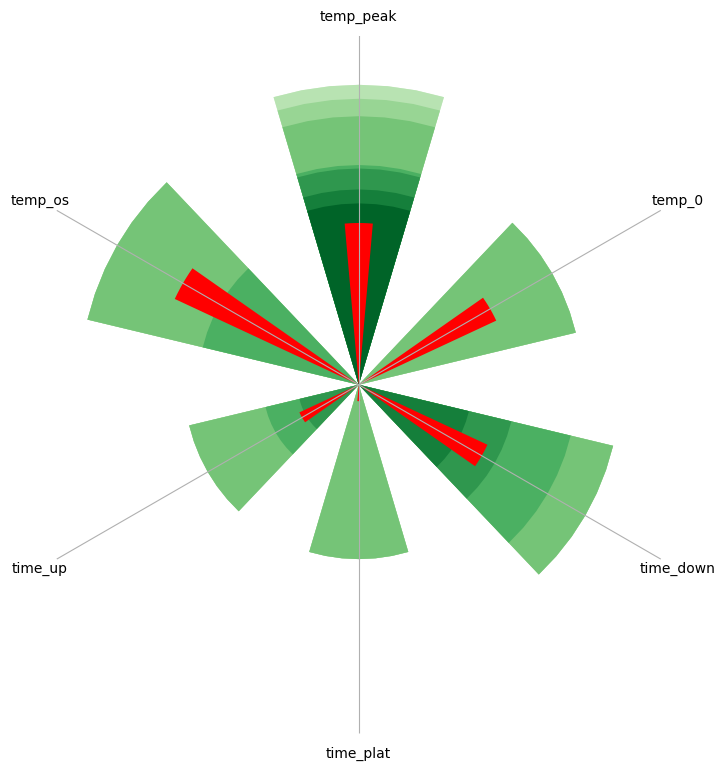

In [395]:
r_sort = np.sort(r_data,axis=1)[:,::-1]
r_sn = np.copy(r_sort)
for i in range(len(popt)):
    r_sn[i,:] /= pars[i][-1]

N = len(popt)
theta = radar_factory(N,frame='circle')
fig, ax = plt.subplots(figsize=(9,9),nrows=1,ncols=1,
                            subplot_kw=dict(projection='radar'))
fig.subplots_adjust(wspace=0.25, hspace=0.20, top=0.85, bottom=0.05)

spoke_labels = par_files

# ax.set_rgrids([0,0.2,0.4,0.6,0.8])
ax.set_ylim(0,1)
ax.yaxis.grid(False)
# ax.set_rlabel_position(135)
ax.set_yticks([])
# ax.grid(False)
ax.spines['polar'].set_visible(False)

colors = mpl.colormaps['Greens_r'](np.linspace(0, 1, 11))
reorder = [5,0,1,2,3,4]
for i in range(len(TEs)):
    # ax.fill(theta[reorder], r_sn[:,i], facecolor=colors[8-i], alpha=1, label='_nolegend_');
    ax.bar(theta[reorder], r_sn[:,i],color=colors[8-i],width=1.1*np.pi/N)
ax.set_xticks(theta[reorder],par_files)
# ax.set_yticks([0,0.2,0.4,0.6])
# ax.set_ylim(0.01,1)
# ax.set_varlabels(spoke_labels)
# ax.legend(loc=(0.325,0.125),ncols=2,title='Tipping elements',fontsize=8)
# ax.plot(theta[reorder],[popt[i]/pars[i][-1] for i in range(N)],color='k',marker='x',ms=10)
ax.bar(theta[reorder], [popt[i]/pars[i][-1] for i in range(N)],color='r',width=np.pi/3/N)

rticks = [np.arange(0,2.5+.1,step=0.5), np.arange(0,5.1,step=1), np.arange(0,2.5+.1,step=0.5),
           np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,201,step=50)]
# for i in range(N):
#     traj = ax.plot([theta[reorder[i]]]*len(rticks[i]),rticks[i],color='k',lw=0.5)
    

In [507]:
r_sort

array([[  1.6 ,   1.6 ,   1.6 ,   1.6 ,   0.  ,   0.  ,   0.  ,   0.  ,
          0.  ],
       [  4.3 ,   4.3 ,   4.1 ,   3.85,   3.15,   3.1 ,   2.8 ,   2.6 ,
          0.  ],
       [  2.  ,   2.  ,   2.  ,   2.  ,   1.15,   0.  ,   0.  ,   0.  ,
          0.  ],
       [100.  , 100.  , 100.  , 100.  ,  55.  ,  35.  ,   0.  ,   0.  ,
          0.  ],
       [100.  , 100.  , 100.  , 100.  ,   0.  ,   0.  ,   0.  ,   0.  ,
          0.  ],
       [150.  , 150.  , 150.  , 150.  , 125.  ,  90.  ,  65.  ,   0.  ,
          0.  ]])

In [244]:
theta

array([0.        , 1.04719755, 2.0943951 , 3.14159265, 4.1887902 ,
       5.23598776])

In [224]:
r_sort.shape

(6, 9)

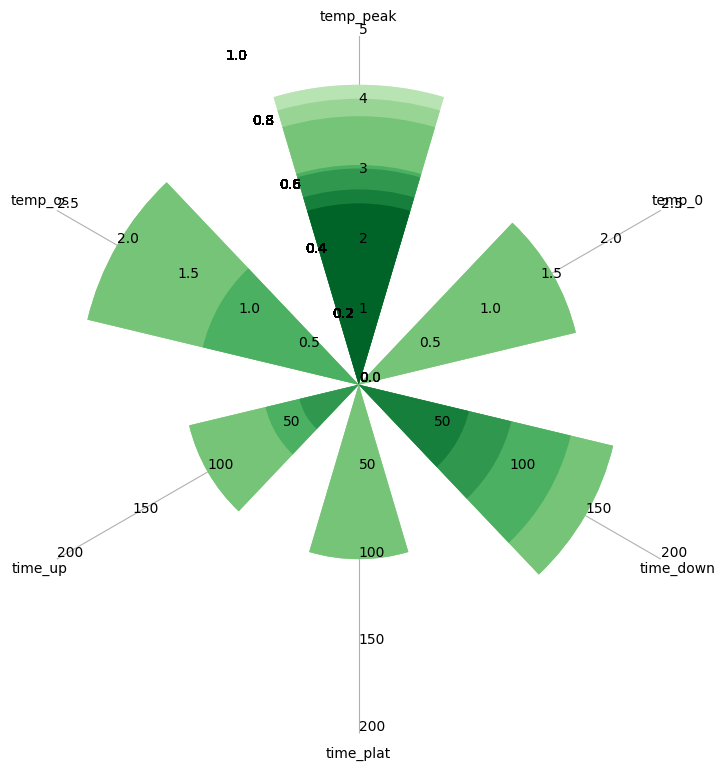

In [292]:
# r_sort = np.sort(r_data,axis=1)[:,::-1]
# r_sn = np.copy(r_sort)
# for i in range(len(popt)):
#     r_sn[i,:] /= pars[i][-1]

N = len(popt)
theta = radar_factory(N,frame='circle')
fig, ax = plt.subplots(figsize=(9,9),nrows=1,ncols=1,
                            subplot_kw=dict(projection='radar'))
fig.subplots_adjust(wspace=0.25, hspace=0.20, top=0.85, bottom=0.05)

spoke_labels = par_files
colors = mpl.colormaps['Greens_r'](np.linspace(0, 1, 11))
reorder = [5,0,1,2,3,4]

# ax.set_rlabel_position(theta[reorder[0]]*180/np.pi)
# ax.bar(theta[reorder]
axs=[]
rtickss = [np.arange(0,2.6,step=0.5), np.arange(0,5.1,step=1), np.arange(0,2.6,step=0.5),
           np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,201,step=50)]

for j in range(N):
    for i in range(len(TEs)):
        axs += [polar_twin(ax)]
        axs[j].bar(theta[reorder[j]], r_sort[j,i],color=colors[8-i],width=1.1*np.pi/N)
        # axs[j].set_rlabel_position(theta[reorder[j]]*180/np.pi)
    axs[j].set_ylim(pars[j][0],pars[j][-1])
    # axs[j].tick_params(axis='y', which='major', color='k')
    axs[j].set_rgrids(rtickss[j], angle=theta[reorder[j]]*180/np.pi)
ax.set_xticks(theta[reorder],par_files)

ax.set_ylim(0,1)
ax.yaxis.grid(False)
ax.set_yticks([])
# ax.grid(False)
ax.spines['polar'].set_visible(False)
# ax.set_yticks([])
# ax.set_ylim(0.01,1)
# ax.set_varlabels(spoke_labels)
# ax.legend(loc=(0.325,0.125),ncols=2,title='Tipping elements',fontsize=8)
# ax.plot(theta[reorder],[popt[i]/pars[i][-1] for i in range(N)],color='k',marker='x',ms=10)
# ax.bar(theta[reorder], [popt[i]/pars[i][-1] for i in range(N)],color='r',width=np.pi/3/N)

# axs = []
# for i in range(N):
#     axs += [fig.add_axes([0,0,1,1],polar=True)]

# ax_Tp = polar_twin(ax)

In [257]:
for i in range(len(popt)):
    print(pars[i][0], pars[i][-1])

0.0 2.5
0.0 5.0
0.0 2.5
0 200
0 200
0 200


In [450]:
class Radar(object):

    def __init__(self, fig, titles, rticks, rect=None,rotate_labels = False):
        if rect is None:
            rect = [0.05, 0.05, 0.95, 0.95]

        self.n = len(titles)
        self.angles = [a if a <=360. else a - 360. for a in np.arange(90, 90+360, 360.0/self.n)] 
        self.axes = [fig.add_axes(rect, projection="polar", label="axes%d" % i) 
                         for i in range(self.n)]
        self.rticks = rticks

        self.ax = self.axes[0]
        self.ax.set_thetagrids(self.angles, labels=titles,)# fontsize=12, weight="bold")
        self.ax.tick_params(axis='x', which='major', pad=16)
        self.ax.yaxis.grid(False)

        if rotate_labels:
            labels = []
            for label, angle in zip(self.ax.get_xticklabels(),self.angles):
                x,y = label.get_position()
                lab = self.ax.text(x,y, label.get_text(), transform=label.get_transform(),
                              ha='center', va='center')
                lab.set_rotation(angle-90)
                labels.append(lab)
            self.ax.set_xticklabels([])

        for ax in self.axes[1:]:
            ax.patch.set_visible(False)
            ax.grid("off")
            ax.xaxis.set_visible(False)    
            ax.yaxis.grid(False)

        # for ax, angle, rtick in zip(self.axes, self.angles, self.rticks):
        #     ax.set_rgrids(rtick, labels = rtick, angle=angle, fontsize=12)
        #     ax.spines["polar"].set_visible(False)
        #     ax.set_rticks(rtick)
        #     # ax.tick_params(axis='x', which='major', pad=15)
            # ax.set_ylim(0, 6)  

    def plot(self, values, *args, **kw):
        angle = np.deg2rad(np.r_[self.angles, self.angles[0]])
        values = np.r_[values, values[0]]
        self.ax.plot(angle, values, *args, **kw)

    def bar(self,values,*args,**kw):
        angles = np.deg2rad(np.r_[self.angles, self.angles[0]])
        values = np.r_[values, values[0]]
        for ax, angle, value in zip(self.axes,angles, values):
            ax.bar(angle,value, *args, **kw)

    def set_rticks(self,rticks, loc_offset=0):
        for ax, angle, rtick in zip(self.axes, self.angles, rticks):
            ax.set_rgrids(rtick, labels = rtick, angle=angle+loc_offset, fontsize=12)
            ax.spines["polar"].set_visible(False)
            ax.set_rticks(rtick)
            

In [420]:
r_sort.shape

(6, 9)

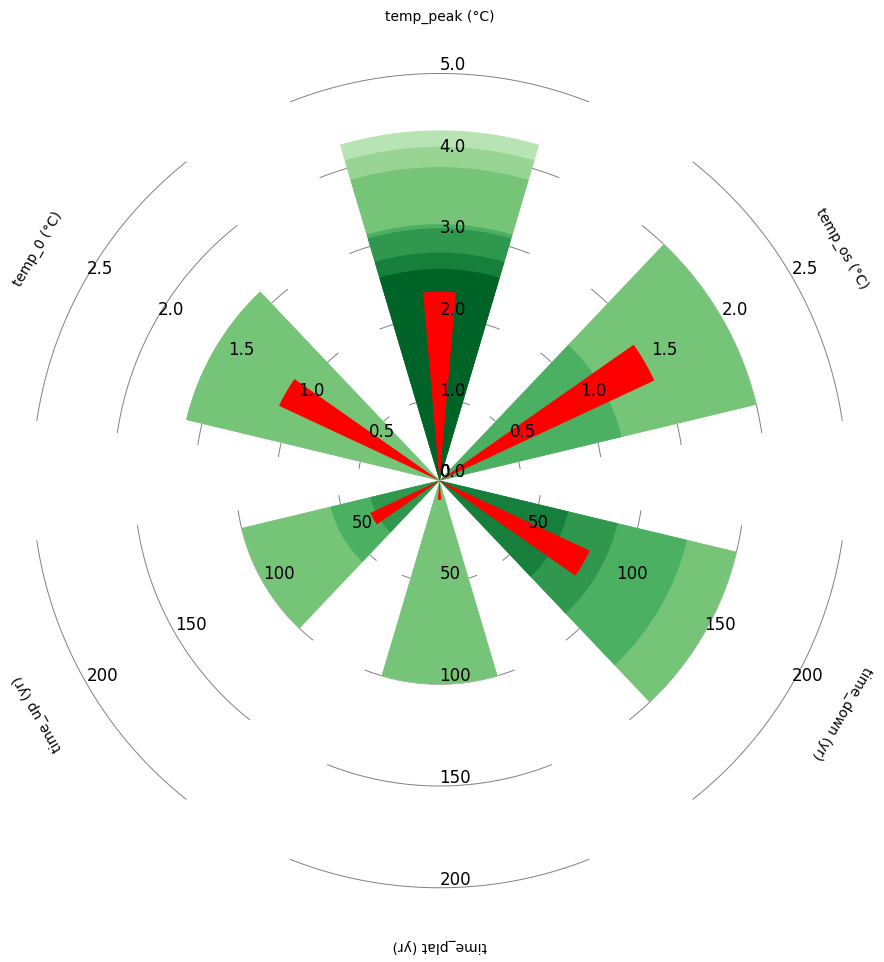

In [467]:
titles = ['temp_peak (°C)', 'temp_0 (°C)', 'time_up (yr)', 'time_plat (yr)', 'time_down (yr)', 'temp_os (°C)']
rticks = [np.arange(0,5.1,step=1), np.arange(0,2.5+.1,step=0.5),
           np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,2.5+.1,step=0.5)]

fig=plt.figure(figsize=(9,9))
radar = Radar(fig, titles, rticks, rotate_labels=True)
radar.set_rticks(rticks,loc_offset = 0)

sim2ax_reorder = [1,0,3,4,5,2]

outer_width = 1.1*np.pi/N
inner_width = np.pi/3/N
width = outer_width+inner_width
for ax, angle in zip(radar.axes, radar.angles):
    # print(angle)
    ax.set_thetagrids([])
    theta1 = np.deg2rad(angle)-width/2
    theta2 = theta1+width
    # ax.plot([theta1]*2,ax.get_ylim(),color='grey',lw = 0.5)
    # ax.plot([theta2]*2,ax.get_ylim(),color='grey',lw = 0.5)
    for r in ax.get_yticks():
        ax.plot(np.linspace(theta1,theta2), [r]*50, color='grey',lw = 0.7,zorder=0)

for i in range(len(TEs)):
    radar.bar(r_sort[sim2ax_reorder,i],color=colors[8-i],width=outer_width)
radar.bar(popt[sim2ax_reorder],color='r',width=inner_width)

## Plotting regular barcharts

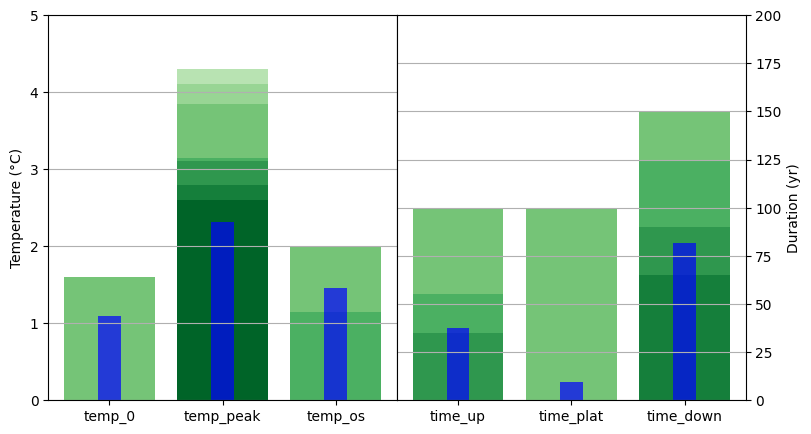

In [502]:
fig,axs=plt.subplots(figsize=(9,5),ncols=2)
fig.subplots_adjust(wspace=0)
colors = mpl.colormaps['Greens_r'](np.linspace(0, 1, 11))
for i in range(len(TEs)):
    axs[0].bar([1,2,3], r_sort[:3,i],color=colors[8-i])
    axs[1].bar([1,2,3], r_sort[3:,i],color=colors[8-i])

axs[0].bar([1,2,3], popt[:3],color='b',width=0.2,alpha=0.7)
axs[1].bar([1,2,3], popt[3:],color='b',width=0.2,alpha=0.7)

axs[0].set_xticks([1,2,3], par_files[:3])
axs[0].set_ylim(0,5)
axs[0].set_ylabel("Temperature (°C)")
axs[0].grid(True,axis='y')

axs[1].set_xticks([1,2,3], par_files[3:])
axs[1].set_ylim(0,200)
axs[1].yaxis.tick_right()
axs[1].set_ylabel("Duration (yr)")
axs[1].yaxis.set_label_position("right")
axs[1].grid(True,axis='y')

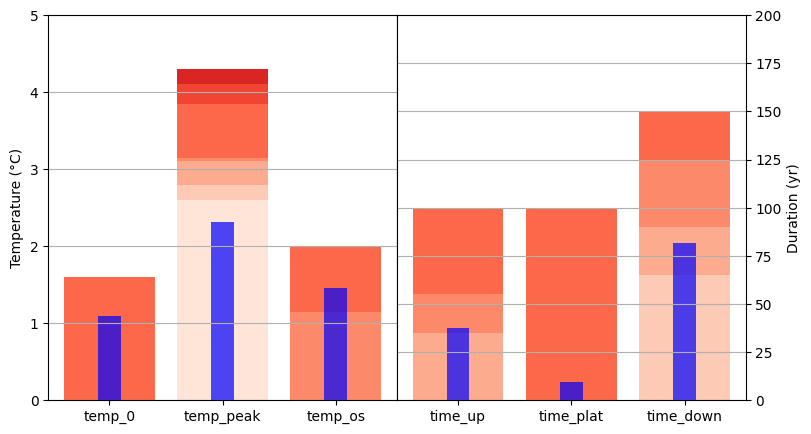

In [506]:
fig,axs=plt.subplots(figsize=(9,5),ncols=2)
fig.subplots_adjust(wspace=0)
colors = mpl.colormaps['Reds'](np.linspace(0, 1, 11))
for i in range(len(TEs)):
    axs[0].bar([1,2,3], r_sort[:3,i],color=colors[8-i])
    axs[1].bar([1,2,3], r_sort[3:,i],color=colors[8-i])

axs[0].bar([1,2,3], popt[:3],color='b',width=0.2,alpha=0.7)
axs[1].bar([1,2,3], popt[3:],color='b',width=0.2,alpha=0.7)

axs[0].set_xticks([1,2,3], par_files[:3])
axs[0].set_ylim(0,5)
axs[0].set_ylabel("Temperature (°C)")
axs[0].grid(True,axis='y')

axs[1].set_xticks([1,2,3], par_files[3:])
axs[1].set_ylim(0,200)
axs[1].yaxis.tick_right()
axs[1].set_ylabel("Duration (yr)")
axs[1].yaxis.set_label_position("right")
axs[1].grid(True,axis='y')

# Final polar bar plots

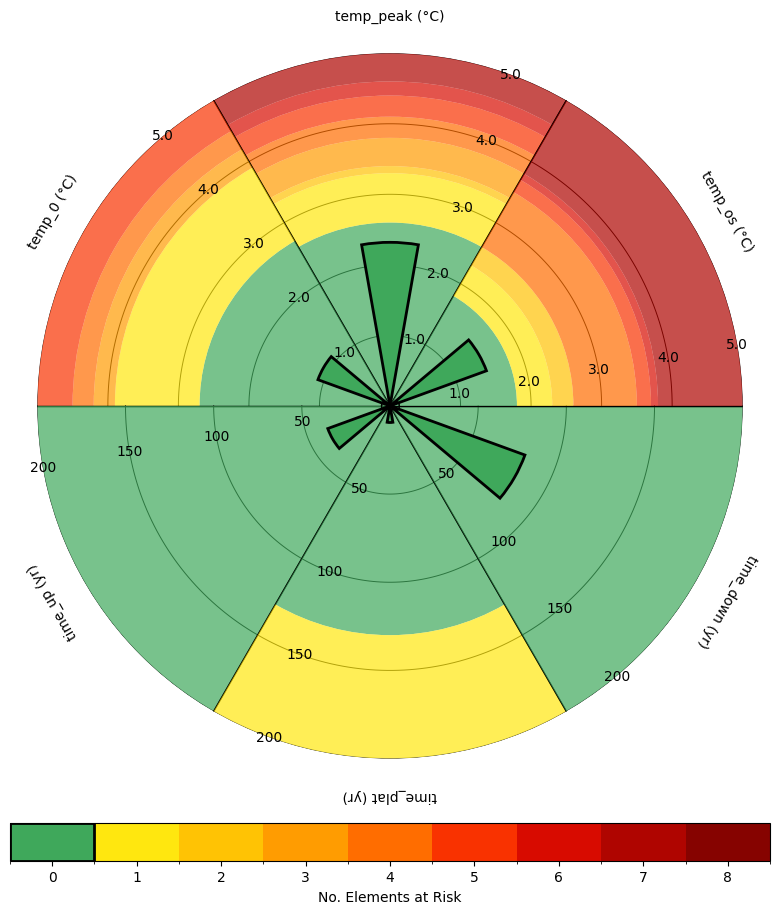

In [114]:
r_data = np.array([critical_parameter(D[i],pars[i],axis=0) for i in range(len(popt))])

titles = ['temp_peak (°C)', 'temp_0 (°C)', 'time_up (yr)', 'time_plat (yr)', 'time_down (yr)', 'temp_os (°C)']
rticks = [np.arange(0,5.1,step=1), np.arange(0,5+.1,step=1),
           np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,5+.1,step=1)]
ylims=[(0,5), (0,5), (0,200), (0,200), (0,200), (0,5)]
N=r_data.shape[0]
outer_width = 360/N
inner_width = 2*180/3/N
width = outer_width+inner_width

fig=plt.figure(figsize=(8,9))
radar = Radar(fig, N, titles=titles, rotate_labels=True, 
              wedge_width = outer_width, with_rlabels=True, 
              ylims=ylims, rticks=rticks,loc_offset=10)

sim2ax_reorder = [1,0,3,4,5,2]
colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
r_noreef = np.delete(r_data, 6, axis=1)
r_sort=np.sort(r_noreef,axis=1)
no_breached = np.sum(popt.reshape(r_sort.shape[0],1) > r_sort,axis=1)
nb = no_breached[0]
hatches=['.','.'] 

c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+r_sort.shape[1]]]
cmap = LinearSegmentedColormap.from_list('my_cmap', c_list, N=len(c_list))
bounds = np.arange(-0.5,9,step=1)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)

for j, ax, angle in zip(range(r_sort.shape[0]), radar.axes, radar.angles):
    r_plot = r_sort[sim2ax_reorder,:][j,:]

    radar.wedge_stacked_bar(ax,angle,r_plot,c_list=c_list)
    radar.wedge_stacked_bar(ax,angle,r_plot[:nb],c_list=c_list,
                            width=np.deg2rad(inner_width),
                            alpha=1,edgecolor='k')
    if nb>0:
        bottom=r_plot[nb-1]
    else:
        bottom=0
    radar.wedge_stacked_bar(ax,angle,[popt[sim2ax_reorder][j]],
                            c_list=[c_list[nb]],
                            width=np.deg2rad(inner_width),
                            alpha=1,edgecolor='k',bottom=bottom,lw=2)

fig.subplots_adjust(bottom=0.2)
# cbar_ax = fig.add_axes([0,-0.1,1,0.1])
cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap,norm=norm),
                    ax=radar.axes,orientation='horizontal',
                    fraction=0.1,pad=0.075,label='No. Elements at Risk',
                    ticks=np.arange(0,9))
rect = mpl.patches.Rectangle((nb-0.5, 0), 1, 1, linewidth=2, edgecolor='k', facecolor='none')
cbar.ax.add_patch(rect)
# cbar.ax.set_xticks([(i+1)/len()])

folder='../../Figures/Overshoots/perturb_around_baseline/'
# fig.savefig(folder+'SOS_%s.png'%baseline,bbox_inches='tight')

In [312]:
r_sort.shape

(6, 8)

## fn to get likelihood of n elements tipping
Basically treat it as the number of successes out of $N$ independent but not (necessarily) identical Bernoulis. 
In other words this is a Poisson Binomial https://en.wikipedia.org/wiki/Poisson_binomial_distribution

So will use sp.stats.poisson_binom (see https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.poisson_binom.html)

In particular for $X_i\sim\text{Bern}(D_i)$ the RV for the i'th element, with Bernoulli parameter $D_i$, let $N_T = \sum_i X_i$ be the number of degraded elements. 

Let global_risk be the risk associated with the sum i.e. $N_T$ not with the individual $X_i$'s

In the end, we will be concerned about cumulative probabilities, so that we can answer at what parameter values does the global risk of $n$ or more elements tip breach $10\%$? That is for parameter $\theta$, we want $\theta_c$ (critical parameter value) at which $P_{\theta_c}(N_T > n) = 0.1$.

Equivalently this means finding $\theta_c$ such that $P_{\theta_c}(N_T > k) = 1-P_{\theta_c}(N_t\leq k)=0.1$ for $n\in \{0,\cdots,N-1\}$ where $N$ is the number of TEs

Let us denote by $\text{AR}_k := P_{\theta_c}(N_T > k)$

NB: applying sample-mean before aggregate_risk is more or less the same as applying sample-mean after but is way slower!

In [296]:
from scipy.stats import poisson_binom

def aggregate_risk(D,k,axis=1):
    shape_list = [a for a in range(len(D.shape))]
    shape_list.append(shape_list.pop(axis))
    if len(shape_list)==1:
        return 1-poisson_binom(k,D)
    else:
        return 1-poisson_binom.cdf(k,np.transpose(D, shape_list))

In [301]:
D_noreef[0].shape

(51, 500, 8, 286)

In [317]:
D_noreef = [np.delete(D[i],6,axis=-2) for i in range(len(popt))]
AR_popt = [np.array([aggregate_risk(D_noreef[i].mean(axis=1),k,axis=1) 
                     for k in range(D_noreef[i].shape[-2])]) 
           for i in tqdm.tqdm(range(len(popt)))]

100%|████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:01<00:00,  3.48it/s]


In [318]:
AR_popt[0].shape

(8, 51, 286)

In [319]:
R_data = np.array([np.max(pars[i].reshape(1,len(pars[i]),1)*(AR_popt[i]<=0.1), axis=1) for i in range(6)]) # R_data to differentiate with r_data

In [320]:
R_data.shape

(6, 8, 286)

Text(0.5, 0, 'temp_os (°C)')

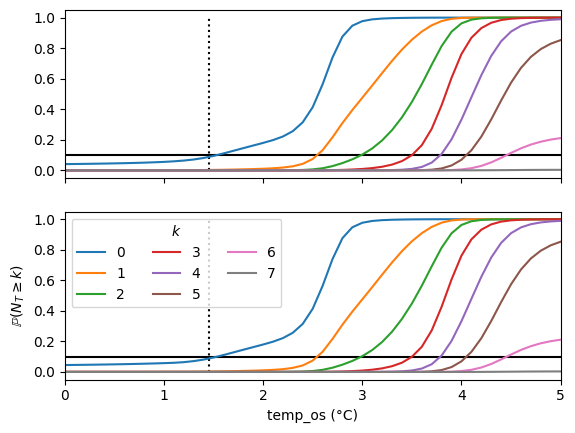

In [323]:
par_names = ['temp_0 (°C)', 'temp_peak (°C)', 'temp_os (°C)', 'time_up (yr)', 'time_plat (yr)', 'time_down (yr)']
i=2
fig,axs=plt.subplots(nrows=2,sharex=True)
for i_ax in range(2):
    axs[i_ax].plot(pars[i][[0,-1]], [0.1]*2,c='k')
    axs[i_ax].plot([popt[i]]*2,[0,1],c='k',ls=':')
for k in range(D_noreef[i].shape[-2]):
    axs[0].plot(pars[i], AR_popt[i][k,:,-1],label=k)
    axs[1].plot(pars[i], AR_popt[i][k,:,:].max(axis=-1),label=k)
plt.legend(ncols=3,title=r'$k$')
plt.ylabel(r"$\mathbb{P}(N_T\geq k)$")
plt.xlim(pars[i][[0,-1]])
plt.xlabel(par_names[i])

In [327]:
titles = ['temp_peak (°C)', 'temp_0 (°C)', 'time_up (yr)', 'time_plat (yr)', 'time_down (yr)', 'temp_os (°C)']
rticks = [np.arange(0,5.1,step=1), np.arange(0,5+.1,step=1),
           np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,5+.1,step=1)]
ylims=[(0,5), (0,5), (0,200), (0,200), (0,200), (0,5)]
N=R_data.shape[0]
outer_width = 360/N
inner_width = 2*180/3/N
width = outer_width+inner_width

fig=plt.figure(figsize=(8,9))
radar = Radar(fig, N, titles=titles, rotate_labels=True, 
              wedge_width = outer_width, with_rlabels=True, 
              ylims=ylims, rticks=rticks,loc_offset=10,wedgetick_lw=2)

sim2ax_reorder = [1,0,3,4,5,2]
colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
# R_noreef = np.delete(r_data, 6, axis=1)
R_sort= R_data[:,:,-1]#np.sort(R_data,axis=1)
no_breached = np.sum(popt.reshape(R_sort.shape[0],1) > R_sort,axis=1)
nb = no_breached[0]
hatches=['.','.'] 

c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+r_sort.shape[1]]]
cmap = LinearSegmentedColormap.from_list('my_cmap', c_list, N=len(c_list))
bounds = np.arange(-0.5,9,step=1)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)

for j, ax, angle in zip(range(r_sort.shape[0]), radar.axes, radar.angles):
    R_plot = R_sort[sim2ax_reorder,:][j,:]

    radar.wedge_stacked_bar(ax,angle,R_plot,c_list=c_list,zorder=0)
    radar.wedge_stacked_bar(ax,angle,R_plot[:nb],c_list=c_list,
                            width=np.deg2rad(inner_width),
                            alpha=1,edgecolor='none',zorder=2)
    if nb>0:
        bottom=R_plot[nb-1]
    else:
        bottom=0
    radar.wedge_stacked_bar(ax,angle,[popt[sim2ax_reorder][j]],
                            c_list=[c_list[nb]],
                            width=np.deg2rad(inner_width),
                            alpha=1,edgecolor='k',
                            bottom=0,#bottom,
                            lw=2,zorder=1)

fig.subplots_adjust(bottom=0.2)
# cbar_ax = fig.add_axes([0,-0.1,1,0.1])
cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap,norm=norm),
                    ax=radar.axes,orientation='horizontal',
                    fraction=0.1,pad=0.075,label='No. Elements at Risk',
                    ticks=np.arange(0,9))
rect = mpl.patches.Rectangle((nb-0.5, 0), 1, 1, linewidth=2, edgecolor='k', facecolor='none')
cbar.ax.add_patch(rect)
# cbar.ax.set_xticks([(i+1)/len()])

folder='../../Figures/Overshoots/perturb_around_baseline/'
# fig.savefig(folder+'SOS_%s.png'%baseline,bbox_inches='tight')

AttributeError: PolarAxes.set() got an unexpected keyword argument 'wedgetick_lw'

<Figure size 800x900 with 0 Axes>

# comparing how 'total' risk evolves versus 'aggregate' risk
Here understanding total/mean risk as $\propto \sum_i \mathbb{P}(X_i=1)$

Whereas aggregate risk is $\mathbb{P}(\sum_i X_i >k) \equiv 1-\mathbb{P}(\sum_i X_i \leq k)$, say for $k=0$, which is the probability that at least $k+1$ elements are degraded

## running the baseline simulation

In [127]:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='GTPR25')
df_TEs[['Threshold (°C) – Min.', 
        'Threshold (°C) – Est.', 
        'Threshold (°C) – Max.']] = df_TEs[['Threshold (°C) – Min.', 
                                            'Threshold (°C) – Est.', 
                                            'Threshold (°C) – Max.']].interpolate(method='linear', axis=1, limit_direction='backward')
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

# Loading pre-saved interaction matrices
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

In [174]:
scenarios

array(['CurPol_SAP', 'CurPol_OS_1.5C', 'ModAct_OS_1.5C', 'ModAct_OS_1C',
       'ModAct_SAP', 'ssp534-over', 'Neg_SAP', 'GS_NZGHG', 'Ren_NZCO2',
       'Neg_NZGHG', 'Ref_1p5', 'Neg_OS_0C', 'LD_NZGHG', 'SP_NZGHG',
       'ssp119'], dtype=object)

In [293]:
bline = 'CurPol_OS_1.5C'
# -------- SIMULATIONS --------------
years = np.arange(1850,2301)
no_years = len(years)

# Modifying collapse probabilities for each year according to each scenario
p_c = np.ones((no_years,len(df_TEs)))
p_c *= q_c

p_r = np.ones((no_years,len(df_TEs)))
p_r *= q_r

for t in range(no_years):
    p_c[t,:] *= temp_response(df[bline].to_numpy()[t], T_lim, betas)
    p_r[t,:] *= (1-temp_response(df[bline].to_numpy()[t], T_lim, betas))

D_baseline = np.zeros((len_sample,len(df_TEs),no_years))
for r in tqdm.tqdm(range(len_sample)):
    for t in range(1,no_years):
        D_baseline[r,:,t] = environmental_update(D_baseline[r,:,t-1],A[r],pc=p_c[t,:],pr=p_r[t,:])

100%|███████████████████████████████████████████████████████████████████████████████| 500/500 [00:03<00:00, 146.16it/s]


In [294]:
D_nr_baseline = np.delete(D_baseline,6,axis=1)
TR = D_nr_baseline.mean(axis=(0,1)) # total risk
AR = np.array([aggregate_risk(D_nr_baseline,k,axis=1) 
               for k in range(D_nr_baseline.shape[1]+1)] )

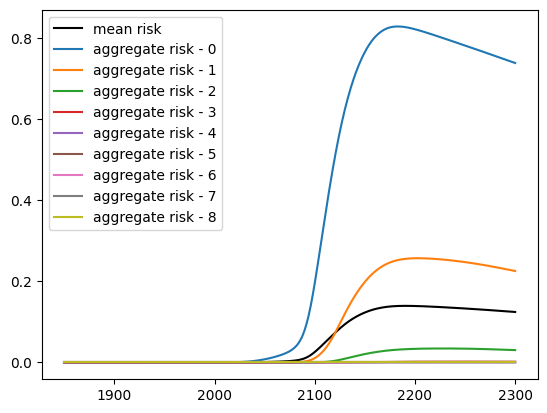

In [295]:
plt.plot(years,TR,label='mean risk',c='k')
# plt.plot(years,AR.mean(axis=0),label='AR-0')
for k in range(AR.shape[0]):
    plt.plot(years,AR[k,:,:].mean(axis=0),label='aggregate risk - %d'%(k))
plt.legend()
# plt.yscale('log')
# plt.xlim(2015,2300)

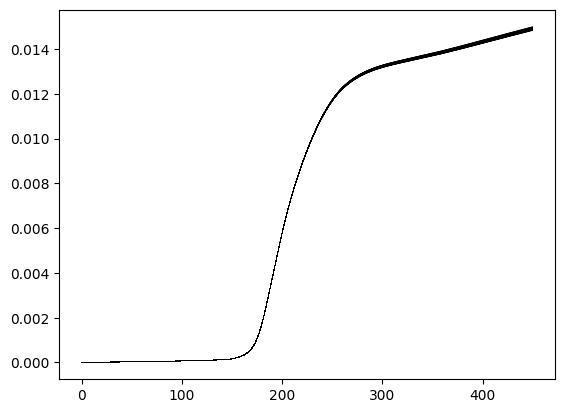

In [281]:
for i in range(500):
    plt.plot(AR_t[i,:],lw=0.1,c='k')
# plt.plot(years,AR[0,:],label='old')
# plt.plot(years,AR_t.mean(axis=0),label='transposed')

# plt.plot(years,AR[0,:] - AR_t.mean(axis=0),label='transposed')

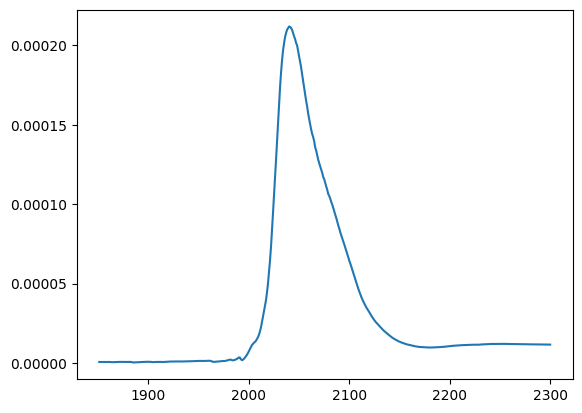

In [213]:
plt.plot(years[:-1]+1,np.diff(AR[0,:]))
# plt.yscale('log')

In [191]:
D_nr_baseline.shape

(500, 8, 451)

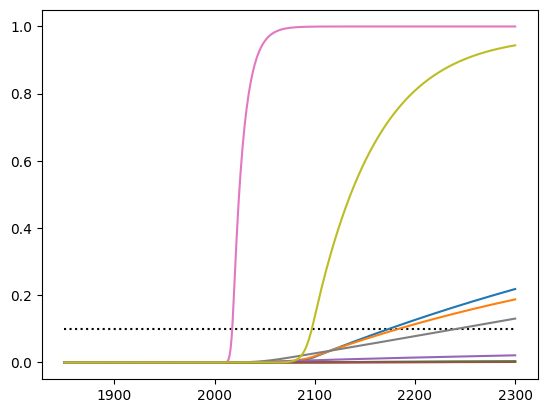

In [283]:
# plt.plot(years,AR[0,:],c='k',label='AR1')
plt.plot(years[[0,-1]],[0.1]*2,c='k',ls=':')
for i in range(D_baseline.shape[1]):
    plt.plot(years,D_baseline.mean(axis=0)[i,:])